In [1]:
#imports
from deel.lip.model import Model 
from deel.lip.layers import SpectralConv2D, SpectralDense,  ScaledGlobalAveragePooling2D
from deel.lip.activations import  GroupSort2
from deel.lip.losses import  TauCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam
from deel.lip.normalizers import set_stop_grad_spectral
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import BatchNormalization, Input,  Softmax
import os, shutil, json
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
import mplhep as hep
import tagger.plot.style as style
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.models import load_model

2025-07-16 12:21:09.239965: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1752668469.261744  734979 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1752668469.268733  734979 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1752668469.286055  734979 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1752668469.286074  734979 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1752668469.286076  734979 computation_placer.cc:177] computation placer alr

In [2]:
#functions for plotting ROC curves (slighlty modified)

def ROC(y_pred, y_test, class_labels, plot_dir,ROC_dict):
    # Create a colormap for unique colors
    colormap = cm.get_cmap('Set1', len(class_labels))  # Use 'tab10' with enough colors

    # Create a plot for ROC curves
    fig,ax = plt.subplots(1,1,figsize=style.FIGURE_SIZE)
    hep.cms.label(llabel=style.CMSHEADER_LEFT,rlabel=style.CMSHEADER_RIGHT,ax=ax, fontsize=style.CMSHEADER_SIZE)
    for i, class_label in enumerate(class_labels):

        # Get true labels and predicted probabilities for the current class
        y_true = y_test[:, i]  # Extract the one-hot column for the current class
        y_score = y_pred[:, i] # Predicted probabilities for the current class

        # Compute FPR, TPR, and AUC
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)

        ROC_dict[class_label] = roc_auc
        # Plot the ROC curve for the current class
        ax.plot(tpr, fpr, label=f'{style.CLASS_LABEL_STYLE[class_label]} (AUC = {roc_auc:.2f})',
                 color=colormap(i), linewidth=style.LINEWIDTH)

    # Plot formatting
    ax.grid(True)
    ax.set_ylabel('Mistag Rate')
    ax.set_xlabel('Signal Efficiency')

    auc_list = [value for key,value in ROC_dict.items()]
    handles, labels = plt.gca().get_legend_handles_labels()
    order = np.argsort(auc_list)
    ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order],loc='upper left',ncol=2,fontsize=style.SMALL_SIZE-3)

    ax.set_yscale('log')
    ax.set_ylim([1e-3, 1.1])

    # Save the plot
    #save_path = os.path.join(plot_dir, "basic_ROC")
    #plt.savefig(f"{save_path}.pdf", bbox_inches='tight')
    #plt.savefig(f"{save_path}.png", bbox_inches='tight')
    #plt.close()

    return ROC_dict
def basic(model_dir):
    """
    Plot the basic ROCs for different classes. Does not reflect L1 rate
    Returns a dictionary of ROCs for each class
    """
    
    plot_dir = os.path.join(model_dir, "plots/training")

    #Load the metada for class_label
    with open(f"{model_dir}/class_label.json", 'r') as file: class_labels = json.load(file)
    with open(f"{model_dir}/input_vars.json", 'r') as file: input_vars = json.load(file)

    ROC_dict = {class_label : 0 for class_label in class_labels} 
    
    #Load the testing data
    X_test = np.load(f"{model_dir}/testing_data/X_test.npy")
    y_test = np.load(f"{model_dir}/testing_data/y_test.npy")
    truth_pt_test = np.load(f"{model_dir}/testing_data/truth_pt_test.npy")
    reco_pt_test = np.load(f"{model_dir}/testing_data/reco_pt_test.npy")
    indices = np.random.permutation(16) 
    #print(indices) 
    #X_test = X_test[:, indices, :] 
    #Load model
    X = tf.expand_dims(X_test, axis=1)
    model = load_model(f"{model_dir}/model/saved_model.h5")
    model_outputs = model.predict(X)

    #Get classification outputs
    y_pred = model_outputs
    #y_pred = tf.nn.softmax(y_pred_l, axis=-1).numpy()
    #pt_ratio = model_outputs[1].flatten()
    
    #Plot ROC curves
    ROC_dict = ROC(y_pred, y_test, class_labels, plot_dir,ROC_dict)

    #Generate all possible pairs of classes
    for i in class_labels.keys():
        for j in class_labels.keys():
            if i != j:
                class_pair = (i,j)
                #ROC_binary(y_pred, y_test, class_labels, plot_dir, class_pair)        

    

    return ROC_dict

In [3]:
#Model
input_shape = (28, 28, 1)
num_classes=10
inputs = Input(shape=(1,16,20), name='model_input')
print(inputs.shape)
#Main branch
inputs = BatchNormalization(name='norm_input')(inputs)
x = SpectralConv2D(10,kernel_size=(1, 1))(inputs)
x = GroupSort2()(x)
x = SpectralConv2D(10,kernel_size=(1, 1))(x)
x = GroupSort2()(x)
x = ScaledGlobalAveragePooling2D()(x)
x = SpectralDense(32)(x)
x = GroupSort2()(x)
x = SpectralDense(16)(x)
x = GroupSort2()(x)
y = SpectralDense(8)(x)
y = Softmax()(y) 
Lip_model = Model(inputs=inputs, outputs=y)
Lip_model.summary()

(None, 1, 16, 20)


2025-07-16 12:21:18.911921: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_SYSTEM_DRIVER_MISMATCH: system has unsupported display driver / cuda driver combination
2025-07-16 12:21:18.911950: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:178] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2025-07-16 12:21:18.911957: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] retrieving CUDA diagnostic information for host: hm01.dice.priv
2025-07-16 12:21:18.911962: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:190] hostname: hm01.dice.priv
2025-07-16 12:21:18.912052: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:197] libcuda reported version is: 575.57.8
2025-07-16 12:21:18.912073: I external/local_xla/xla/stream_exec

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensorCLONE (InputLayer)  │ (None, 1, 16, 20)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d                 │ (None, 1, 16, 10)      │           421 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2 (GroupSort2)        │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d_1               │ (None, 1, 16, 10)      │           221 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_1 (GroupSort2)      │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_global_average_pooling2d │ (None, 10)             │             0 │
│ (ScaledGlobalAveragePooling2D)  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense (SpectralDense)  │ (None, 32)             │           705 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_2 (GroupSort2)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_1                │ (None, 16)             │         1,057 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_3 (GroupSort2)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_2                │ (None, 8)              │           273 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 8)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,677 (10.46 KB)

 Trainable params: 1,336 (5.22 KB)

 Non-trainable params: 1,341 (5.24 KB)

In [4]:
#sample data to train with
import numpy as np
model_dir="output/deepset_HGQ_new" # chnage tahat to dir you have saved test data
X_test = np.load(f"{model_dir}/testing_data/X_test.npy")
y_test = np.load(f"{model_dir}/testing_data/y_test.npy")

In [5]:
#compile step
Lip_model.compile(
   
    loss=TauCategoricalCrossentropy(tau=100),
    optimizer=Adam(1e-3),
    metrics=["accuracy", TauCategoricalCrossentropy(tau=100)],
)

Lip_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensorCLONE (InputLayer)  │ (None, 1, 16, 20)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d                 │ (None, 1, 16, 10)      │           421 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2 (GroupSort2)        │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d_1               │ (None, 1, 16, 10)      │           221 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_1 (GroupSort2)      │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_global_average_pooling2d │ (None, 10)             │             0 │
│ (ScaledGlobalAveragePooling2D)  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense (SpectralDense)  │ (None, 32)             │           705 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_2 (GroupSort2)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_1                │ (None, 16)             │         1,057 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_3 (GroupSort2)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_2                │ (None, 8)              │           273 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 8)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,677 (10.46 KB)

 Trainable params: 1,336 (5.22 KB)

 Non-trainable params: 1,341 (5.24 KB)

In [6]:
#training step
nb_epochs = 80
batch_size = 1024
X = tf.expand_dims(X_test, axis=1)
Lip_model.fit(
    X,
    y_test,
    batch_size=batch_size,
    epochs=nb_epochs,
    validation_data=(X, y_test),
    shuffle=True,
    verbose=1,
    #callbacks = callbacks
)

Epoch 1/80


546/546 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - TauCategoricalCrossentropy: 0.5054 - accuracy: 0.2269 - loss: 0.5054 - val_TauCategoricalCrossentropy: 0.1367 - val_accuracy: 0.3044 - val_loss: 0.1367
Epoch 2/80
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - TauCategoricalCrossentropy: 0.1850 - accuracy: 0.2817 - loss: 0.1850 - val_TauCategoricalCrossentropy: 0.1842 - val_accuracy: 0.3324 - val_loss: 0.1842
Epoch 3/80
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - TauCategoricalCrossentropy: 0.1147 - accuracy: 0.2924 - loss: 0.1147 - val_TauCategoricalCrossentropy: 0.0665 - val_accuracy: 0.3388 - val_loss: 0.0665
Epoch 4/80
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - TauCategoricalCrossentropy: 0.0592 - accuracy: 0.3250 - loss: 0.0592 - val_TauCategoricalCrossentropy: 0.0286 - val_accuracy: 0.3871 - val_loss: 0.0286
Epoch 5/80
546/546 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - TauCategoricalCrossentropy: 0.0272 - accuracy: 0.3693 - loss: 0.0272 - val_TauCategoricalCrossentropy: 0.0248 - val_accuracy: 0

In [7]:
#save model
out_dir="deel_lip"
export_path = os.path.join(out_dir, "model/saved_model.h5")
Lip_model.save(export_path)

17455/17455 ━━━━━━━━━━━━━━━━━━━━ 10s 559us/step


/tmp/ipykernel_734979/4114887433.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap('Set1', len(class_labels))  # Use 'tab10' with enough colors


{'b': 0.7772346308659466,
 'charm': 0.6323349852395024,
 'light': 0.6375557435857442,
 'gluon': 0.7599371045102712,
 'taup': 0.8710623025623498,
 'taum': 0.8865711857147608,
 'muon': 0.9890721033351706,
 'electron': 0.9552077057793763}

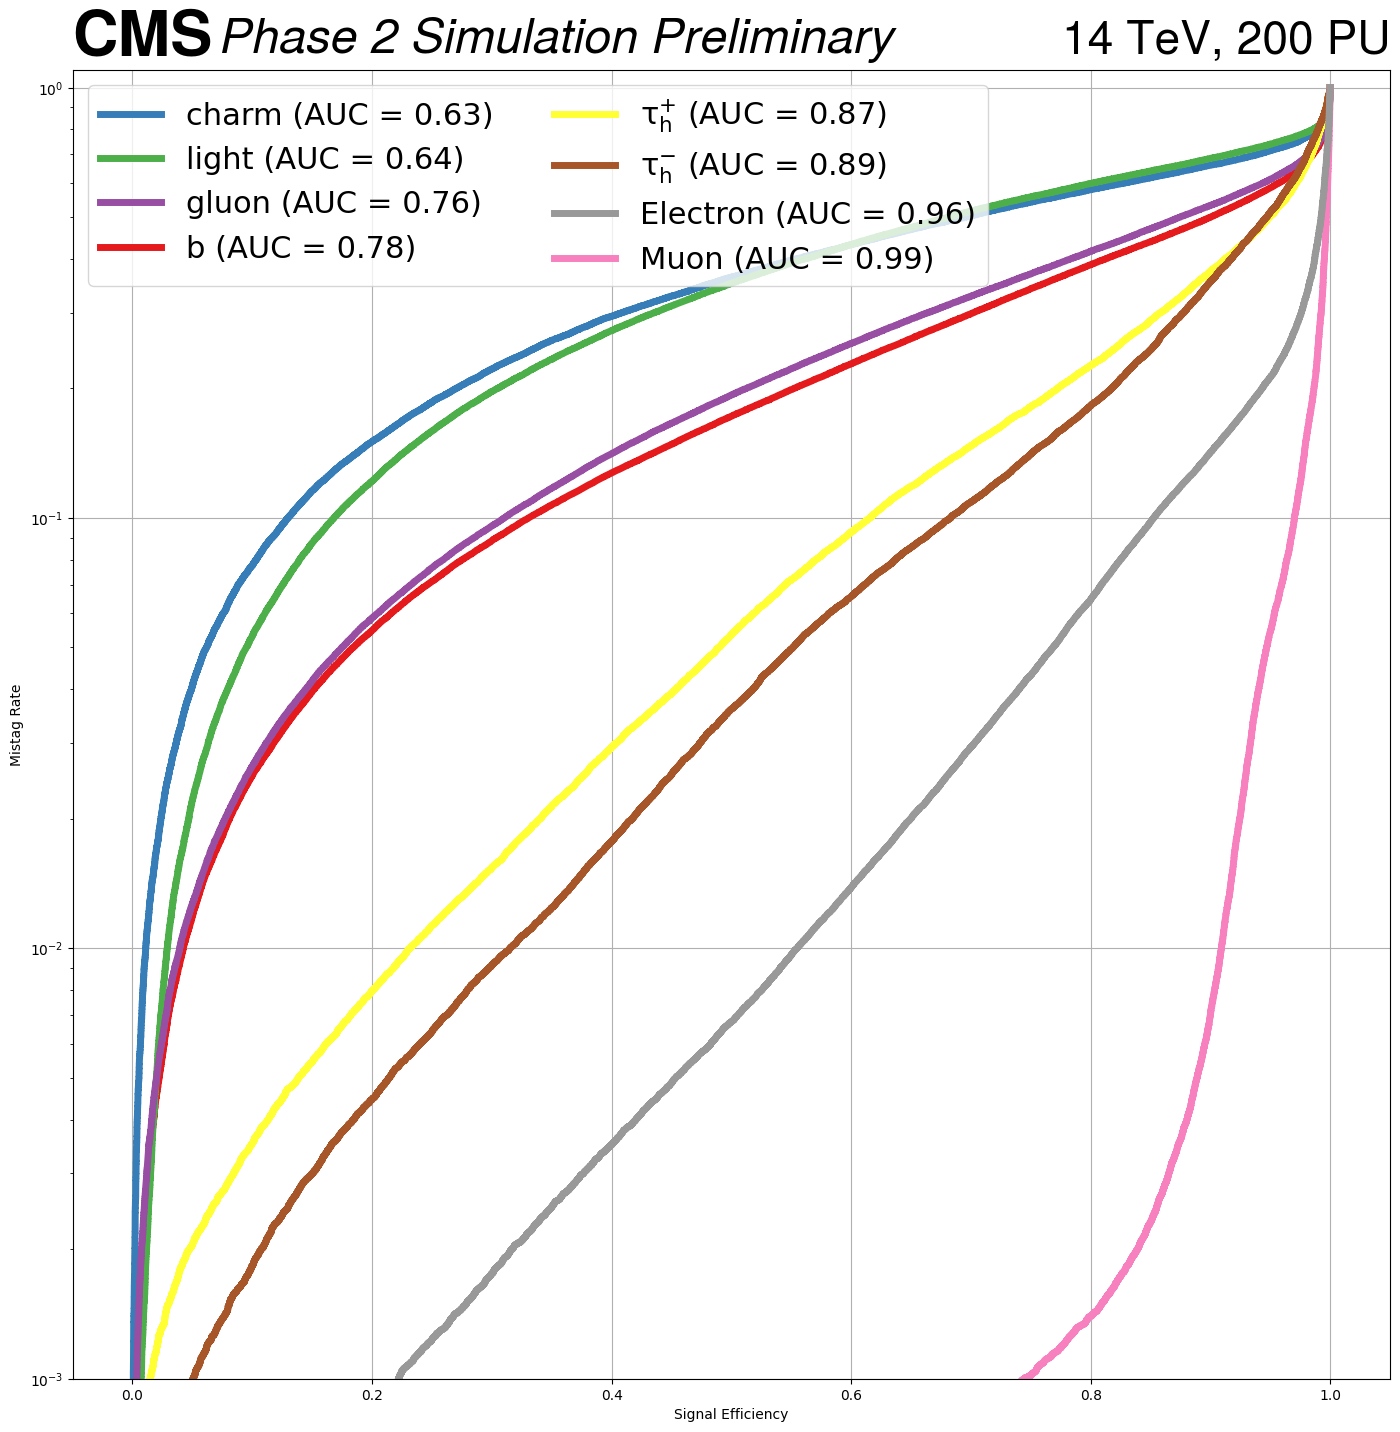

In [8]:
#plot ROC curve
basic("deel_lip/")

### NOTES

TauCategoricalCrossentropy: Similar to the classes we have seen in "Getting started 1", the TauCategoricalCrossentropy class inherits from its equivalent in keras, but it comes with an additional settable parameter named 'temperature' and denoted as: tau. This parameter will allow to adjust the robustness of our model. The lower the temperature is, the more robust our model becomes, but it also becomes less accurate.

ReLU: create a strong vanishing gradient effect. If you manage to learn with it, please call 911.

this notebook should work with a tagger env and: `pip install git+https://github.com/deel-ai/deel-lip.git@keras3`